# Systematic CpG probe removal: effect on clock performance

Investigates what happens when entire CpG probes are **systematically absent
from every sample** — simulating whole-assay failures, QC-failed probe batches,
or array technologies that do not cover a genomic region.

This differs from the random masking in notebook 03 in two key ways:

- **Same probes are removed from every sample** at each level, not a random
  per-sample draw.
- **Removal is ordered by a strategy** (variance, mean methylation, or vocab
  position), so the degradation curve reflects what happens when you lose the
  least — or most — informative probes first.

An overlay of the random masking curve from notebook 03 is included so you can
directly compare: if systematic removal hurts more than random masking at the
same fraction, those specific probes carry disproportionate signal.

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [7]:
from pathlib import Path
import numpy as np
import gc

# ── Which clocks ──────────────────────────────────────────────────
# None = "age" + every best_head_<clock>.pt found in HEAD_PATH
CLOCKS     = None

IMPUTATION = "per_cpg"

# Cohorts used to build the per-CpG reference: EpiHydra's training cohorts.
# Must not overlap DATASET_IDS, or held-out values would leak into the imputation.
REFERENCE_DATASET_IDS = [
    "GSE40279", "GSE55763", "GSE111629", "GSE157131",
    "GSE42861", "GSE169156", "GSE210255",
]

# ── Paths ────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_ROOT   = ROOT / "data/02_processed"
DATA_PATH     = ROOT / "data/03_final/combined_test/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"   # MethylGPT backbone + vocab + args.json
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks3_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261115_120827"
LORA_CKPT     = EPIHYDRA_PATH / "best_model.pt"    

# ── Model settings (must match training) ─────────────────────────
NUM_HEADS  = 4 # N clocks exlcuding "age" (chron age)

# ── Data split ────────────────────────────────────────────────────
SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
BATCH_SIZE   = 16
RANDOM_STATE = 42

# ── Analysis 1: synthetic masking curve ───────────────────────────
# Fractions of CpGs to additionally mask on top of real missingness
MASK_FRACTIONS = np.round(np.arange(0.0, 1.0, 0.1), 2).tolist()
MASK_SEED      = 42    # for reproducibility across fractions

# ── Analysis 2: real coverage bins ────────────────────────────────
N_COVERAGE_BINS = 5    # number of equal-width bins from 0 % to 100 %
MIN_BIN_SAMPLES = 3    # bins with fewer samples are dropped

# ── Output ────────────────────────────────────────────────────────
SAVE_DIR = None        # Path to save figures, or None

# ── Analysis: systematic probe removal ───────────────────────────────────────
# Removal order strategy: "high_variance" (most informative first),
# "mean" (most extreme methylation first), or "low_variance" (least informative first)
REMOVAL_STRATEGY  = "high_variance"
# Fractions of vocab CpGs to remove at each step
REMOVAL_FRACTIONS = MASK_FRACTIONS   # reuse the same levels as notebook 03

# Whether to load a pre-run random masking result for overlay comparison.
# Set to a path string (e.g. "mask_results.csv") or None to skip the overlay.
RANDOM_RESULTS_CSV = '/work/gr-fe/bryan/EpiHydra/results/mask_results.csv'

## Imports

In [9]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import torch
import pandas as pd

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from evaluation import eval_utils as eu 
from epihydra import VocabWrapper, build_multiclock_dataloaders, evaluate
from clocks.epigenetic_clocks import (
    build_cpg_reference,     
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clock_names = eu.resolve_clocks(CLOCKS, HEAD_PATH)

print(f"Using device: {device}")
print(f"Evaluating clocks: '{clock_names}'")

Using device: cuda
Evaluating clocks: '['age', 'hannum_age', 'horvath_age', 'phenoage_age']'


## Load data, config and vocab

In [3]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
Saved training scalers are reused where available. Any clock without one (typically `"age"`) gets a fresh scaler fitted on this training split.

In [4]:
scalers = eu.load_scalers(HEAD_PATH, EPIHYDRA_PATH)

dataloader = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clock_names,
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scalers      = scalers,   # reused where available, fitted otherwise
    mask_ratio   = 0,
    **SPLIT_RATIOS,
)

scalers = dataloader["scalers"]         # the scalers actually used, one per clock

Samples in meta : 1239
Samples in CpG  : 1239
Common samples  : 1239
Samples after drop : 1239
  age                 : 1239 labeled
  hannum_age          : 1239 labeled
  horvath_age         : 1239 labeled
  phenoage_age        : 1239 labeled

Vocab CpGs : 49,159 | Present : 45,069 (91.7%) | Missing : 4,090
ℹ  age                 : reusing supplied pre-fitted scaler.
ℹ  hannum_age          : reusing supplied pre-fitted scaler.
ℹ  horvath_age         : reusing supplied pre-fitted scaler.
ℹ  phenoage_age        : reusing supplied pre-fitted scaler.
✓ Single multi-clock loader built (1239 samples, no masking).



/work/gr-fe/bryan/EpiHydra/epihydra/epihydra.py:125: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(X, axis=0)                  # (n_cpgs,) — NaN where all-NaN probe


## Build the multi-clock model
Frozen, LoRA-merged backbone + one trained head per clock.

In [5]:
mc_model  = eu.build_multiclock_model(MODEL_PATH, vocab, pretrain_config, device,
                                      ckpt=EPIHYDRA_PATH, head_path=HEAD_PATH,
                                      clock_names=clock_names)

I0000 00:00:1794823167.569455 3703424 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794823173.545523 3703424 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794823194.971078 3703424 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


LoRA from checkpoint: r=16, alpha=32


/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739/best_model.pt
  source run   : nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739
  source epoch : 28  (valid MAE 3.119)
  lora_r=16 lora_alpha=32 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt
  loaded head hannum_age           <- best_head_hannum_age.pt (epoch 61)
  loaded head horvath_age          <- best_head_horvath_age.pt (epoch 47)
  loaded head phenoage_age         <- best_head_phenoage_age.pt (epoch 47)


## Per-CpG reference (training cohorts only)

For each clock CpG, the reference value is the average of its per-cohort medians across
`REFERENCE_DATASET_IDS` (EpiHydra's training cohorts). Only the clock CpGs are kept from
each file, so memory stays small. The held-out cohorts are never used here.

In [10]:
needed_probes = set(vocab.CpG_list)

reference = None
if IMPUTATION == "per_cpg":
    ref_parts = {}
    for gse in REFERENCE_DATASET_IDS:
        with open(DATA_ROOT / gse / "methylation.pkl", "rb") as f:
            cpg_ref = pickle.load(f)["CpG"]
        ref_parts[gse] = cpg_ref.loc[cpg_ref.index.intersection(list(needed_probes))]
        del cpg_ref
        gc.collect()

IMPUTE_REF_SERIES = build_cpg_reference(ref_parts, cpgs=set(vocab.CpG_list))   # ref_parts: training cohorts only
IMPUTE_REF        = eu.reference_by_token(IMPUTE_REF_SERIES, vocab, device)

Reference values for 49,156 of 49,159 vocab CpGs


## Baseline predictions
Establishes unmasked performance before any probes are removed. The loader is rebuilt unshuffled so rows stay aligned to sample IDs.

In [14]:
loader = eu.ordered_loader(dataloader['loader'])
predictions  = eu.predict_multiclock(mc_model, loader, scalers, device, clock_names, impute_ref=IMPUTE_REF)

print(f"{len(predictions)} samples x {len(clock_names)} clocks")

1239 samples x 4 clocks


In [15]:
# Baseline per-clock metrics (pred vs. true for the same clock only)
baseline_rows = []
for name in clock_names:
    sub = predictions[[f"{name}_pred", f"{name}_true"]].dropna()
    p, t = sub.iloc[:, 0].to_numpy(), sub.iloc[:, 1].to_numpy()
    if len(p) < 2:
        continue
    from scipy.stats import pearsonr
    from sklearn.metrics import r2_score
    baseline_rows.append({
        "clock"    : name,
        "n"        : len(p),
        "mae"      : round(float(np.mean(np.abs(p - t))), 3),
        "pearson_r": round(float(pearsonr(p, t)[0]), 3),
        "r2"       : round(float(r2_score(t, p)), 3),
    })

baseline = pd.DataFrame(baseline_rows).set_index("clock")
print("Baseline performance (0 % extra masking)")
display(baseline)

Baseline performance (0 % extra masking)


,n,mae,pearson_r,r2
clock,,,,
age,1239,4.313,0.939,0.878
hannum_age,1239,2.848,0.975,0.944
horvath_age,1239,3.002,0.964,0.929
phenoage_age,1239,4.110,0.955,0.911


## Systematic probe removal

CpGs are ranked once by the chosen strategy, then removed in that fixed order from every sample simultaneously at each fraction level.

In [16]:
ranked_indices, strategy_label = eu.rank_cpgs(
    dataloader['df'],
    strategy = REMOVAL_STRATEGY,
)
print(f"Removal strategy : {strategy_label}")
print(f"Total CpGs ranked: {len(ranked_indices):,}")
print(f"First 5 to remove: vocab positions {ranked_indices[:5]}")

Removal strategy : descending variance (most variable first)
Total CpGs ranked: 49,159
First 5 to remove: vocab positions [44811  8123 44601  1881 35109]


/work/gr-fe/bryan/EpiHydra/evaluation/eval_utils.py:619: RuntimeWarning: Degrees of freedom <= 0 for slice.
  stat = np.nanvar(X, axis=0)


In [26]:
systematic_results = pd.read_csv('/work/gr-fe/bryan/EpiHydra/results/systematic_results.csv', index_col=0)

# systematic_results = eu.evaluate_systematic_removal( mc_model, dataloader['loader'], scalers, device, clock_names,
#                                        ranked_indices = ranked_indices, removal_fractions=REMOVAL_FRACTIONS, impute_ref=IMPUTE_REF)


base = 1 - eu.compute_sample_coverage(dataloader["df"]).mean()
systematic_results["total_missing"] = base + systematic_results["removal_frac"] * (1 - base)

systematic_results.to_csv('/work/gr-fe/bryan/EpiHydra/results/systematic_results.csv')



print(systematic_results.round(3).to_string(index=False))

       clock  removal_frac  n_removed  total_missing    n     mae  pearson_r      r2
         age           0.0          0          0.110 1239   4.666      0.939   0.867
  hannum_age           0.0          0          0.110 1239   3.153      0.978   0.935
 horvath_age           0.0          0          0.110 1239   3.092      0.963   0.920
phenoage_age           0.0          0          0.110 1239   3.953      0.958   0.917
         age           0.1       4915          0.199 1239   7.417      0.924   0.728
  hannum_age           0.1       4915          0.199 1239   4.356      0.960   0.868
 horvath_age           0.1       4915          0.199 1239   3.849      0.957   0.883
phenoage_age           0.1       4915          0.199 1239   6.788      0.946   0.767
         age           0.2       9831          0.288 1239   7.195      0.912   0.758
  hannum_age           0.2       9831          0.288 1239   4.349      0.956   0.868
 horvath_age           0.2       9831          0.288 1239   4.409

In [28]:
dataloader['df']['data']

GSM2250273    [nan, nan, nan, 0.777531048286021, 0.803579478...
GSM2250274    [nan, nan, nan, 0.783327336288178, 0.767147347...
GSM2250275    [nan, nan, nan, 0.79570733462318, 0.8066799695...
GSM2250276    [nan, nan, nan, 0.781230595666587, 0.799998051...
GSM2250277    [nan, nan, nan, 0.796176242678314, 0.800311605...
                                    ...                        
GSM5414847    [nan, nan, nan, 0.873485275637184, 0.776046511...
GSM5414848    [nan, nan, nan, 0.849360832515177, 0.786179130...
GSM5414849    [nan, nan, nan, 0.869756131816948, 0.765446774...
GSM5414850    [nan, nan, nan, 0.850880555278613, 0.772829590...
GSM5414851    [nan, nan, nan, 0.829791752050092, 0.808721679...
Name: data, Length: 1239, dtype: object

Loaded random masking results from /work/gr-fe/bryan/EpiHydra/results/mask_results.csv


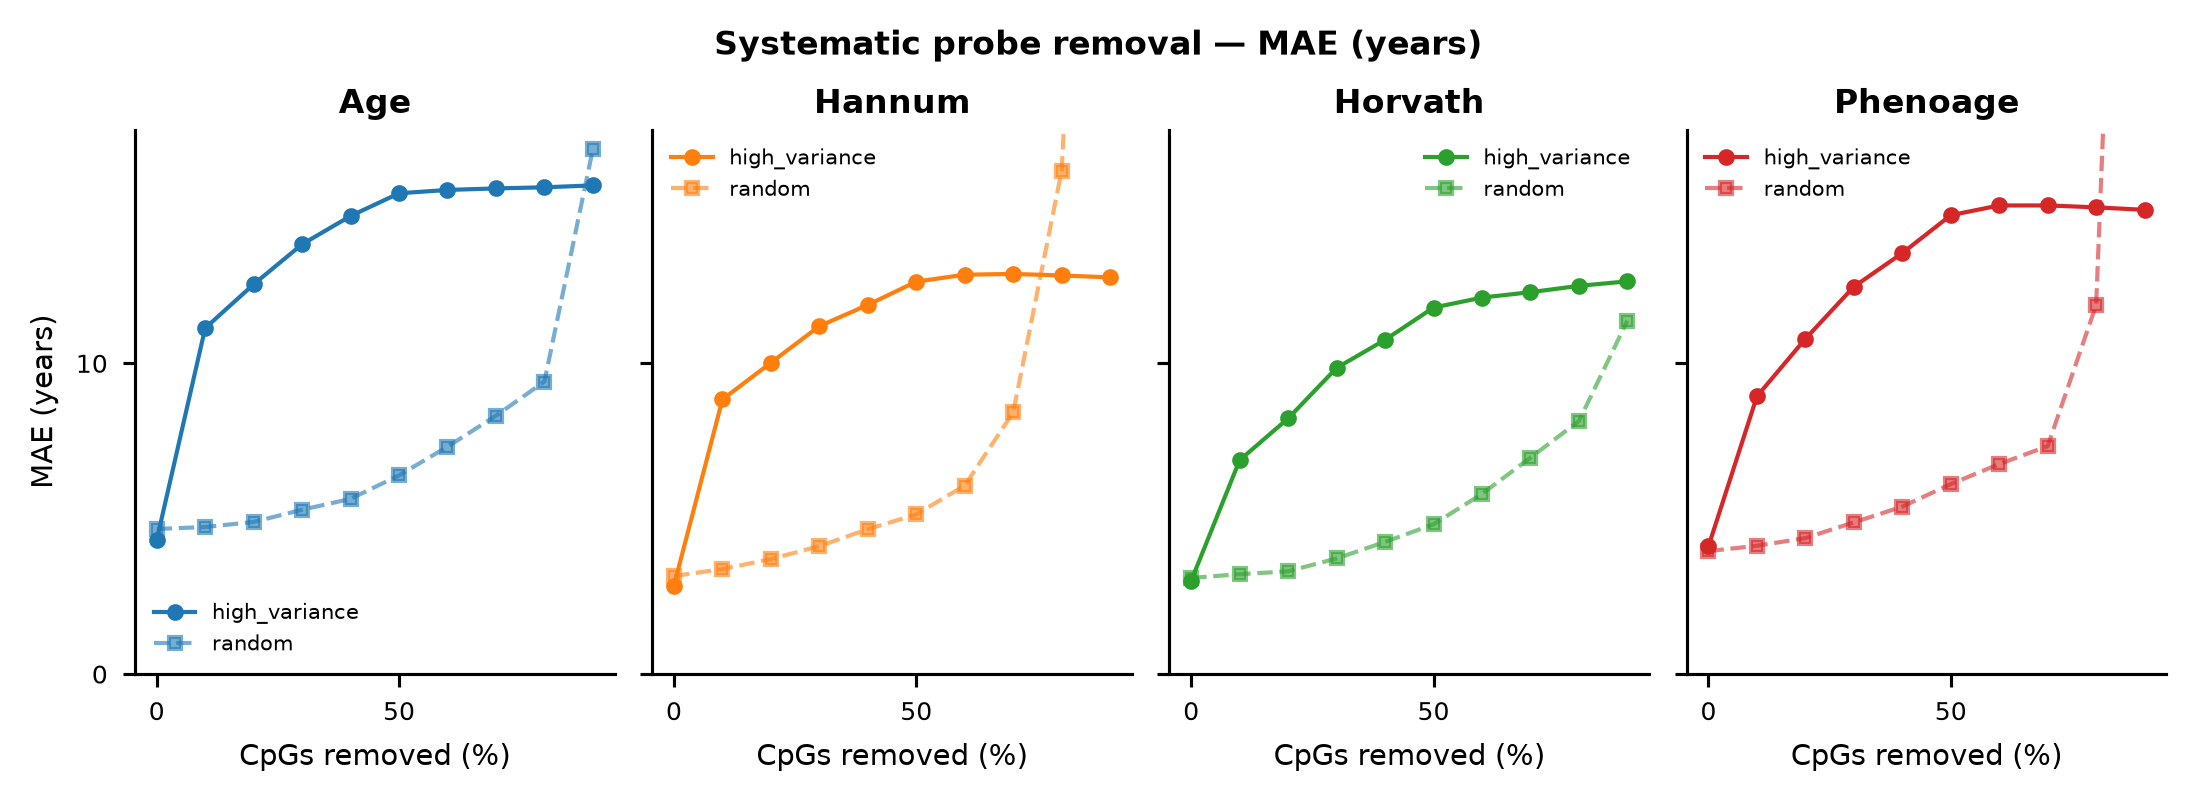

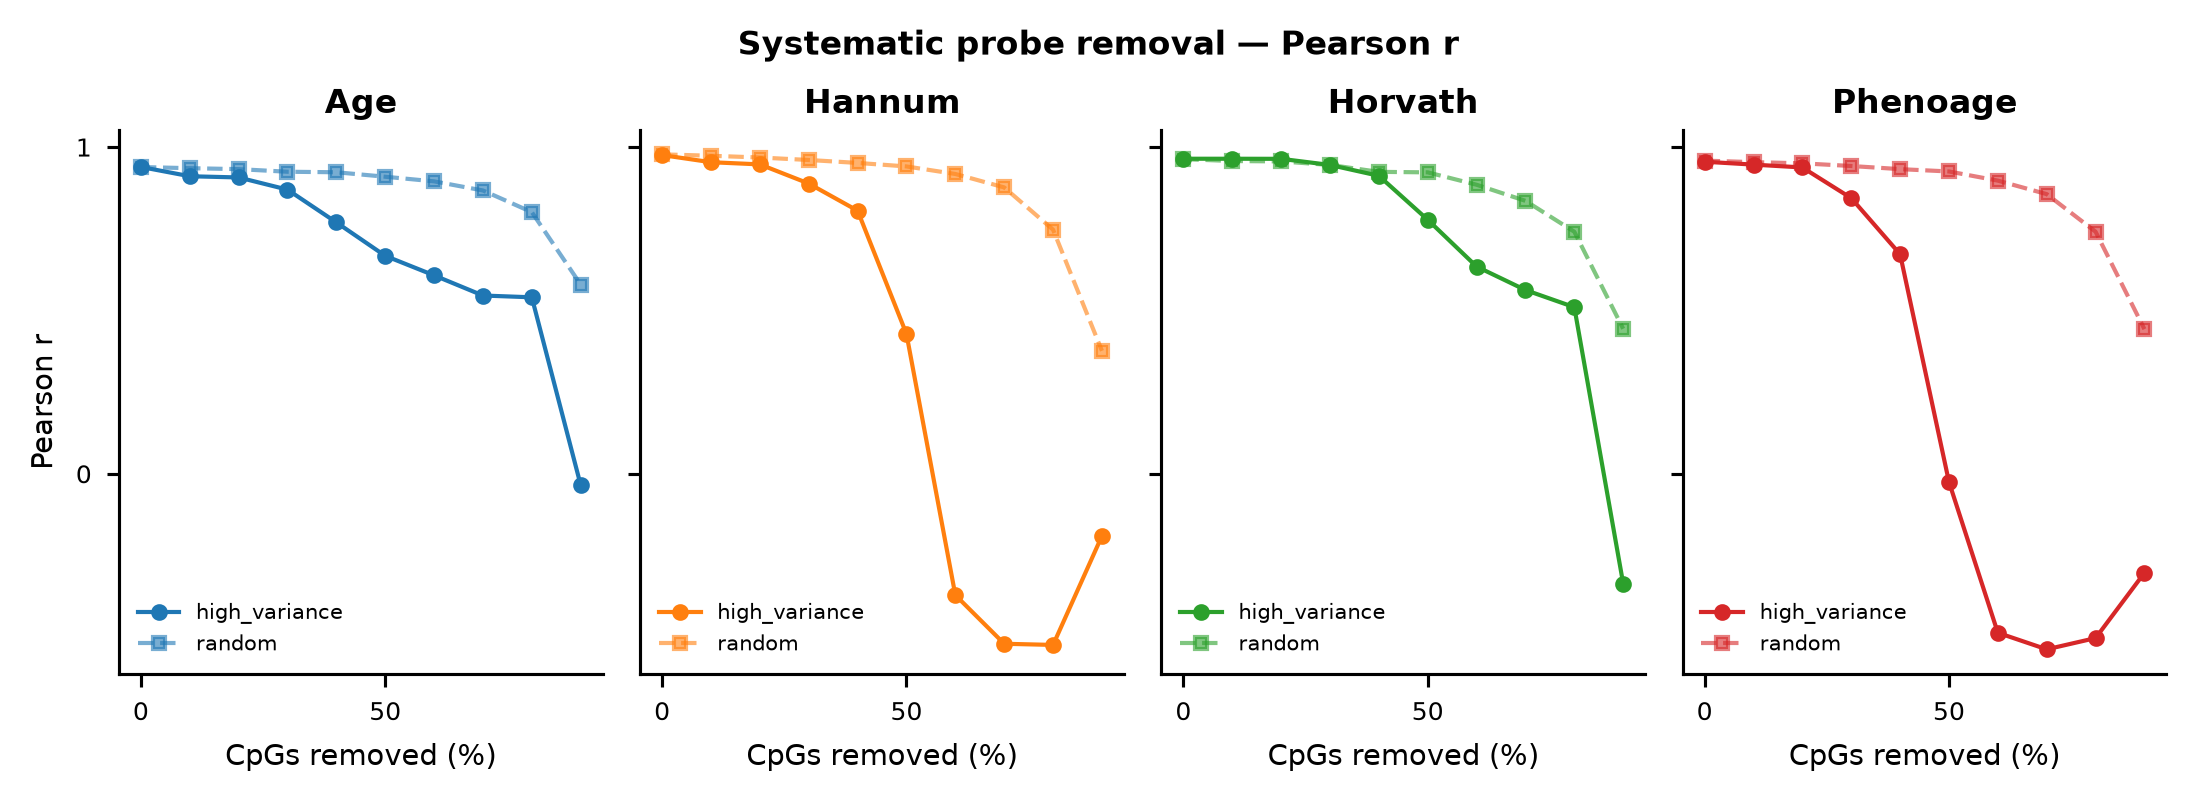

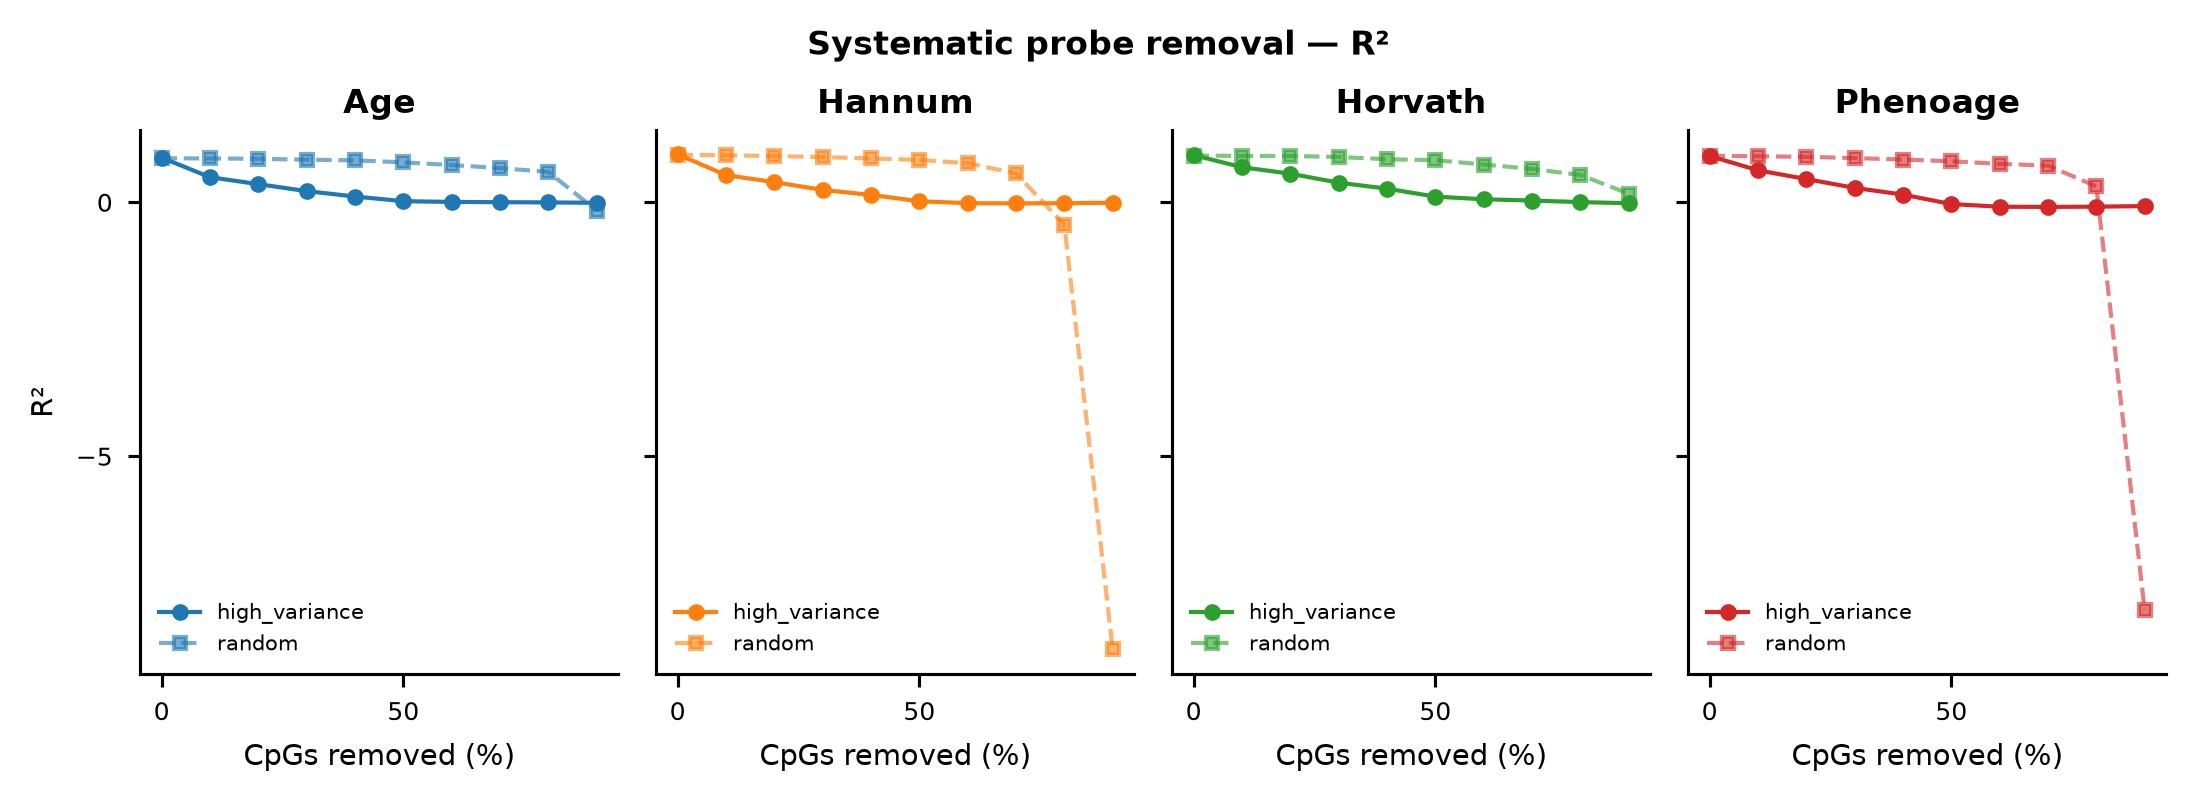

In [22]:
# Optionally load a pre-computed random masking result for overlay comparison
random_results = None
if RANDOM_RESULTS_CSV is not None:
    random_results = pd.read_csv(RANDOM_RESULTS_CSV)
    print(f"Loaded random masking results from {RANDOM_RESULTS_CSV}")

for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_systematic_removal_curves(
        systematic_results,
        random_results = random_results.rename(columns = {'mask_frac' : 'removal_frac'}),
        metric         = metric,
        clock_names    = clock_names,
        strategy_label = REMOVAL_STRATEGY,
        x = 'removal_frac'
    )
    if SAVE_DIR:
        fig.savefig(Path(SAVE_DIR) / f"systematic_removal_{metric}.pdf")
        fig.savefig(Path(SAVE_DIR) / f"systematic_removal_{metric}.png")
    plt.show()

## Removal strategy comparison

Runs all three strategies and overlays the degradation curves per clock. If `"variance"` and `"mean"` produce identical curves the effect is driven by quantity of missing data alone. If `"variance"` degrades more slowly, the model is robust to losing low-information probes and relies on a smaller set of high-variance ones.

In [ ]:
import pickle

In [ ]:
with open('/work/gr-fe/bryan/EpiHydra/results/systematic_results.pkl' , 'wb') as file : 
    pickle.dump(strategy_dfs , file )

In [ ]:
COMPARE_METRIC = "mae"

strategy_dfs = {REMOVAL_STRATEGY : systematic_results}
other_strats = [strat for strat in ["low_variance", "high_variance", "mean"] if strat != REMOVAL_STRATEGY]

for strat in other_strats :
    r_idx, r_label = eu.rank_cpgs(dataloader['df'], strategy=strat)
    res = eu.evaluate_systematic_removal(
        mc_model, loader, scalers, device,
        clock_names       = clock_names,
        ranked_indices    = r_idx,
        removal_fractions = REMOVAL_FRACTIONS,
    )
    strategy_dfs[strat] = res

with plt.rc_context(eu._NM_RC):
    n      = len(clock_names)
    fig_w  = min(183, 55 * n) / 25.4
    fig, axes = plt.subplots(1, n, figsize=(fig_w, 65 / 25.4),
                             sharey=True, constrained_layout=True)
    if n == 1:
        axes = [axes]

    colors  = {"low_variance": "#2166AC", "high_variance": "#D6604D", "mean": "#4DAC26"}
    linesty = {"low_variance": "-",       "high_variance": "--",      "mean": "-."}

    for ax, name in zip(axes, clock_names):
        for strat, (df, label) in strategy_dfs.items():
            sub = df[df["clock"] == name].sort_values("removal_frac")
            ax.plot(sub["removal_frac"] * 100, sub[COMPARE_METRIC],
                    color=colors[strat], ls=linesty[strat], lw=1.0,
                    marker="o", markersize=2.5, label=strat)
        ax.set_title(eu._clean(name), pad=4, fontweight="bold")
        ax.set_xlabel("CpGs removed (%)")
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, fontsize=5)

    ylabel = {"mae": "MAE (years)", "pearson_r": "Pearson r", "r2": "R²"}[COMPARE_METRIC]
    axes[0].set_ylabel(ylabel)
    fig.suptitle(f"Removal strategy comparison — {COMPARE_METRIC}",
                 fontsize=8, fontweight="bold")

if SAVE_DIR:
    fig.savefig(Path(SAVE_DIR) / f"strategy_comparison_{COMPARE_METRIC}.pdf")
    fig.savefig(Path(SAVE_DIR) / f"strategy_comparison_{COMPARE_METRIC}.png")
plt.show()

## Summary: baseline vs. worst removal

Compare unmasked baseline to performance at the highest removal fraction, for the chosen strategy.

In [ ]:
worst_frac = max(REMOVAL_FRACTIONS)
worst_syst = systematic_results[
    systematic_results["removal_frac"] == worst_frac
].set_index("clock")

summary = baseline[["mae", "pearson_r", "r2"]].copy()
summary.columns = [f"baseline_{c}" for c in summary.columns]
for metric in ("mae", "pearson_r", "r2"):
    summary[f"syst_{metric}"]        = worst_syst[metric]
    summary[f"delta_syst_{metric}"]  = (
        summary[f"syst_{metric}"] - summary[f"baseline_{metric}"]
    ).round(3)

print(f"Strategy: {REMOVAL_STRATEGY} | worst fraction: {worst_frac:.0%}")
display(summary.round(3))